# TMDB Movie Data Analysis
This notebook fetches movie data from the TMDb API, cleans and transforms it with Pandas, computes performance KPIs, and visualizes key insights.

## Setup
### Import libraries and project modules

In [1]:
# ===== Setup =====
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fetch import fetch_movies, load_raw_movies, MOVIE_IDS
from src.clean import (
    drop_irrelevant_columns, extract_json_columns, extract_credits,
    inspect_value_counts, convert_dtypes, handle_unrealistic_values,
    remove_invalid_rows, finalize, save_processed,
)
from src import kpis
from src import visualize as viz

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "movies_raw.json"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Step 1: Fetch Movie Data from the API
### Fetch movies from TMDb (or load saved raw data)

In [2]:
# ===== Step 1: Fetch movie data from the TMDb API =====
# Calls the API only the first time; afterwards loads the saved raw JSON.
if RAW_PATH.exists():
    df_raw = load_raw_movies(RAW_PATH)
    print(f"Loaded raw data from {RAW_PATH}")
else:
    df_raw = fetch_movies(MOVIE_IDS, save_path=RAW_PATH)

print("Shape:", df_raw.shape)
df_raw.head()

[skip] movie_id=0: 404 Client Error: Not Found for url: https://api.themoviedb.org/3/movie/0?append_to_response=credits
Fetched 18 of 19 movies.
Raw data saved to c:\Users\PC\Desktop\Amalitech1\tmdb-movie-analysis\data\raw\movies_raw.json
Shape: (18, 28)


,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count,credits
0,False,/7RyHsO4yDXtBv1zUU3mTpHeQ0d5.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",356000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 878, ...",https://www.marvel.com/movies/avengers-endgame,299534,tt4154796,[US],en,Avengers: Endgame,After the devastating events of Avengers: Infi...,85.69,/bR8ISy1O9XQxqiy0fQFw2BX72RQ.jpg,"[{'id': 420, 'logo_path': '/hUzeosd33nzE5MCNsZ...","[{'iso_3166_1': 'US', 'name': 'United States o...",2019-04-24,2927449455,181,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Avenge the fallen.,Avengers: Endgame,False,8.20,29012,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
1,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",237000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://www.avatar.com/movies/avatar,19995,tt0499549,[US],en,Avatar,"In the 22nd century, a paraplegic Marine is di...",54.77,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg,"[{'id': 444, 'logo_path': None, 'name': 'Dune ...","[{'iso_3166_1': 'US', 'name': 'United States o...",2009-12-16,2923706026,162,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Enter the world of Pandora.,Avatar,False,7.61,34850,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
2,False,/8BTsTfln4jlQrLXUBquXJ0ASQy9.jpg,"{'id': 10, 'name': 'Star Wars Collection', 'po...",245000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",http://www.starwars.com/films/star-wars-episod...,140607,tt2488496,[US],en,Star Wars: The Force Awakens,Thirty years after defeating the Galactic Empi...,33.93,/wqnLdwVXoBjKibFRR5U3y0aDUhs.jpg,"[{'id': 1, 'logo_path': '/tlVSws0RvvtPBwViUyOF...","[{'iso_3166_1': 'US', 'name': 'United States o...",2015-12-15,2068223624,136,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Every generation has a story.,Star Wars: The Force Awakens,False,7.24,21018,"{'cast': [{'adult': False, 'gender': 1, 'id': ..."
3,False,/mDfJG3LC3Dqb67AZ52x3Z0jU0uB.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",300000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",https://www.marvel.com/movies/avengers-infinit...,299536,tt4154756,[US],en,Avengers: Infinity War,As the Avengers and their allies have continue...,120.25,/7WsyChQLEftFiDOVTGkv3hFpyyt.jpg,"[{'id': 420, 'logo_path': '/hUzeosd33nzE5MCNsZ...","[{'iso_3166_1': 'US', 'name': 'United States o...",2018-04-25,2052415039,149,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,An entire universe. Once and for all.,Avengers: Infinity War,False,8.24,33155,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
4,False,/xXCuto8YVp5RFqBJ7yKmVmLOWpF.jpg,None,200000000,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",https://www.paramountmovies.com/movies/titanic,597,tt0120338,[US],en,Titanic,101-year-old Rose DeWitt Bukater tells the sto...,57.50,/9xjZS2rlVxm8SFx8kPC3aIGCOYQ.jpg,"[{'id': 4, 'logo_path': '/jay6WcMgagAklUt7i9Eu...","[{'iso_3166_1': 'US', 'name': 'United States o...",1997-12-18,2264162353,194,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Nothing on earth could come between them.,Titanic,False,7.90,27904,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."


### Inspect the raw data structure

In [3]:
# ===== Inspect the raw data structure =====
print("Columns:\n", list(df_raw.columns))
print()
df_raw.info()

Columns:
 ['adult', 'backdrop_path', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'origin_country', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'softcore', 'spoken_languages', 'status', 'tagline', 'title', 'video', 'vote_average', 'vote_count', 'credits']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  18 non-null     bool   
 1   backdrop_path          18 non-null     object 
 2   belongs_to_collection  16 non-null     object 
 3   budget                 18 non-null     int64  
 4   genres                 18 non-null     object 
 5   homepage               18 non-null     object 
 6   id                     18 non-null     int64  
 7   imdb_id         

### Explore the JSON-like columns

In [4]:
# ===== Look at JSON-like columns to understand their structure =====
for col in ["belongs_to_collection", "genres", "spoken_languages"]:
    print(f"{col}: {df_raw[col].iloc[0]}\n")

belongs_to_collection: {'id': 86311, 'name': 'The Avengers Collection', 'poster_path': '/yFSIUVTCvgYrpalUktulvk3Gi5Y.jpg', 'backdrop_path': '/2UNUv4NJdC36E5myDHACBJ99EwL.jpg'}

genres: [{'id': 12, 'name': 'Adventure'}, {'id': 878, 'name': 'Science Fiction'}, {'id': 28, 'name': 'Action'}]

spoken_languages: [{'english_name': 'English', 'iso_639_1': 'en', 'name': 'English'}, {'english_name': 'Japanese', 'iso_639_1': 'ja', 'name': '日本語'}, {'english_name': 'Xhosa', 'iso_639_1': 'xh', 'name': ''}]



## Step 2: Data Cleaning and Preprocessing
### Drop irrelevant columns

In [5]:
# ===== Step 2: Drop irrelevant columns =====
df = drop_irrelevant_columns(df_raw)
print("Remaining columns:", df.shape[1])

Remaining columns: 23


### Extract key data from JSON-like columns and credits

In [6]:
# ===== Flatten JSON-like columns and extract credits =====
df = extract_json_columns(df)
df = extract_credits(df)

df[["title", "belongs_to_collection", "genres", "spoken_languages",
    "production_countries", "director", "cast_size", "crew_size"]].head()

,title,belongs_to_collection,genres,spoken_languages,production_countries,director,cast_size,crew_size
0,Avengers: Endgame,The Avengers Collection,Adventure|Science Fiction|Action,English|Japanese|Xhosa,United States of America,Joe Russo|Anthony Russo,103,613
1,Avatar,Avatar Collection,Science Fiction|Action|Adventure,English|Spanish,United States of America|United Kingdom,James Cameron,68,999
2,Star Wars: The Force Awakens,Star Wars Collection,Adventure|Action|Science Fiction,English,United States of America,J.J. Abrams,99,270
3,Avengers: Infinity War,The Avengers Collection,Adventure|Action|Science Fiction,English|Xhosa,United States of America,Joe Russo|Anthony Russo,69,738
4,Titanic,NaN,Drama|Romance,English|French|German|Swedish|Italian|Russian,United States of America,James Cameron,116,271



### Inspect extracted columns with value_counts()

In [7]:
# ===== Inspect extracted columns with value_counts() to spot anomalies =====
value_counts = inspect_value_counts(df, top=10)


=== belongs_to_collection (10 unique) ===
belongs_to_collection
The Avengers Collection                4
Star Wars Collection                   2
Jurassic Park Collection               2
Frozen Collection                      2
Avatar Collection                      1
The Lion King (Reboot) Collection      1
The Fast and the Furious Collection    1
Black Panther Collection               1
Harry Potter Collection                1
The Incredibles Collection             1

=== genres (11 unique) ===
genres
Adventure          15
Science Fiction    10
Action             10
Family              5
Animation           4
Fantasy             4
Thriller            3
Drama               2
Romance             2
Crime               1

=== production_countries (2 unique) ===
production_countries
United States of America    18
United Kingdom               2

=== production_companies (20 unique) ===
production_companies
Marvel Studios                   5
Universal Pictures               3
Lightstorm En

### Convert column data types

In [8]:
# ===== Convert data types =====
df = convert_dtypes(df)
df[["id", "budget", "revenue", "popularity", "runtime", "release_date"]].dtypes

id                       int64
budget                   int64
revenue                  int64
popularity             float64
runtime                  int64
release_date    datetime64[ns]
dtype: object

### Handle unrealistic and placeholder values

In [9]:
# ===== Handle unrealistic and placeholder values =====
print("Zeros before cleaning:")
print((df[["budget", "revenue", "runtime"]] == 0).sum())
print("\nMovies with vote_count = 0:", (df["vote_count"] == 0).sum())

df = handle_unrealistic_values(df)

print("\nMissing after cleaning:")
print(df[["budget_musd", "revenue_musd", "runtime", "vote_average", "tagline", "overview"]].isna().sum())

Zeros before cleaning:
budget     0
revenue    0
runtime    0
dtype: int64

Movies with vote_count = 0: 0

Missing after cleaning:
budget_musd     0
revenue_musd    0
runtime         0
vote_average    0
tagline         0
overview        0
dtype: int64


### Remove duplicates and invalid rows, keep only released movies

In [10]:
# ===== Remove duplicates and invalid rows, keep Released movies =====
print("Status counts:\n", df["status"].value_counts(), "\n")
before = len(df)

df = remove_invalid_rows(df, min_non_null=10)

print(f"Rows: {before} -> {len(df)}")

Status counts:
 status
Released    18
Name: count, dtype: int64 

Rows: 18 -> 18


### Reorder columns, reset index, and save the clean dataset

In [11]:
# ===== Reorder columns, reset index, save =====
df = finalize(df)
save_processed(df)

print("Final shape:", df.shape)
df.head()

Clean data saved to C:\Users\PC\Desktop\Amalitech1\tmdb-movie-analysis\data\processed\movies_clean.csv
Final shape: (18, 22)


,id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,poster_path,cast,cast_size,director,crew_size
0,299534,Avengers: Endgame,Avenge the fallen.,2019-04-24,Adventure|Science Fiction|Action,The Avengers Collection,en,356.00,"2,927.45",Marvel Studios,United States of America,29012,8.20,85.69,181,After the devastating events of Avengers: Infi...,English|Japanese|Xhosa,/bR8ISy1O9XQxqiy0fQFw2BX72RQ.jpg,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chr...,103,Joe Russo|Anthony Russo,613
1,19995,Avatar,Enter the world of Pandora.,2009-12-16,Science Fiction|Action|Adventure,Avatar Collection,en,237.00,"2,923.71",Dune Entertainment|Lightstorm Entertainment|20...,United States of America|United Kingdom,34850,7.61,54.77,162,"In the 22nd century, a paraplegic Marine is di...",English|Spanish,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg,Sam Worthington|Zoe Saldaña|Sigourney Weaver|S...,68,James Cameron,999
2,140607,Star Wars: The Force Awakens,Every generation has a story.,2015-12-15,Adventure|Action|Science Fiction,Star Wars Collection,en,245.00,"2,068.22",Lucasfilm Ltd.|Bad Robot,United States of America,21018,7.24,33.93,136,Thirty years after defeating the Galactic Empi...,English,/wqnLdwVXoBjKibFRR5U3y0aDUhs.jpg,Daisy Ridley|John Boyega|Oscar Isaac|Adam Driv...,99,J.J. Abrams,270
3,299536,Avengers: Infinity War,An entire universe. Once and for all.,2018-04-25,Adventure|Action|Science Fiction,The Avengers Collection,en,300.00,"2,052.42",Marvel Studios,United States of America,33155,8.24,120.25,149,As the Avengers and their allies have continue...,English|Xhosa,/7WsyChQLEftFiDOVTGkv3hFpyyt.jpg,Robert Downey Jr.|Chris Evans|Chris Hemsworth|...,69,Joe Russo|Anthony Russo,738
4,597,Titanic,Nothing on earth could come between them.,1997-12-18,Drama|Romance,NaN,en,200.00,"2,264.16",Paramount Pictures|20th Century Fox|Lightstorm...,United States of America,27904,7.90,57.50,194,101-year-old Rose DeWitt Bukater tells the sto...,English|French|German|Swedish|Italian|Russian,/9xjZS2rlVxm8SFx8kPC3aIGCOYQ.jpg,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kath...,116,James Cameron,271


### Final data quality check

In [12]:
# ===== Final data quality check =====
df.info()
print("\nMissing values per column:")
df.isna().sum()[lambda s: s > 0]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     18 non-null     int32         
 1   title                  18 non-null     object        
 2   tagline                18 non-null     object        
 3   release_date           18 non-null     datetime64[ns]
 4   genres                 18 non-null     object        
 5   belongs_to_collection  16 non-null     object        
 6   original_language      18 non-null     object        
 7   budget_musd            18 non-null     float64       
 8   revenue_musd           18 non-null     float64       
 9   production_companies   18 non-null     object        
 10  production_countries   18 non-null     object        
 11  vote_count             18 non-null     int64         
 12  vote_average           18 non-null     float64       
 13  popular

belongs_to_collection    2
dtype: int64

## Exploratory Data Analysis
### Summary statistics

In [13]:
# ===== Exploratory overview =====
df[["budget_musd", "revenue_musd", "vote_count", "vote_average", "popularity", "runtime"]].describe()

,budget_musd,revenue_musd,vote_count,vote_average,popularity,runtime
count,18.00,18.00,18.00,18.00,18.00,18.00
mean,213.78,"1,699.04","21,718.33",7.40,50.04,138.00
std,61.96,537.61,"8,733.60",0.53,23.81,23.85
min,125.00,"1,243.23","10,516.00",6.52,29.66,102.00
25%,162.50,"1,336.18","14,567.75",7.12,34.47,125.25
50%,200.00,"1,484.54","21,515.00",7.26,39.40,135.50
75%,243.00,"1,957.20","27,222.00",7.83,56.82,147.50
max,356.00,"2,927.45","40,041.00",8.24,120.25,194.00


## Step 3: KPI Implementation and Analysis
### Calculate profit and ROI

In [14]:
# ===== Step 3: Add profit and ROI =====
df = kpis.add_financial_metrics(df)
df[["title", "budget_musd", "revenue_musd", "profit_musd", "roi"]].sort_values("roi", ascending=False)

,title,budget_musd,revenue_musd,profit_musd,roi
1,Avatar,237.00,"2,923.71","2,686.71",12.34
4,Titanic,200.00,"2,264.16","2,064.16",11.32
5,Jurassic World,150.00,"1,671.54","1,521.54",11.14
11,Harry Potter and the Deathly Hallows: Part 2,125.00,"1,341.51","1,216.51",10.73
13,Frozen II,150.00,"1,453.68","1,303.68",9.69
15,Frozen,150.00,"1,274.22","1,124.22",8.49
2,Star Wars: The Force Awakens,245.00,"2,068.22","1,823.22",8.44
0,Avengers: Endgame,356.00,"2,927.45","2,571.45",8.22
8,Furious 7,190.00,"1,515.40","1,325.40",7.98
16,Beauty and the Beast,160.00,"1,266.12","1,106.12",7.91


### Best and worst performing movies

In [15]:
# ===== Best / worst performing movies (ranking UDF) =====
rankings = kpis.get_all_rankings(df, n=5)

for name, table in rankings.items():
    print(f"\n=== {name} ===")
    display(table)


=== Highest Revenue ===


,title,revenue_musd
0,Avengers: Endgame,"2,927.45"
1,Avatar,"2,923.71"
2,Titanic,"2,264.16"
3,Star Wars: The Force Awakens,"2,068.22"
4,Avengers: Infinity War,"2,052.42"



=== Highest Budget ===


,title,budget_musd
0,Avengers: Endgame,356.00
1,Avengers: Infinity War,300.00
2,Star Wars: The Last Jedi,300.00
3,The Lion King,260.00
4,Star Wars: The Force Awakens,245.00



=== Highest Profit ===


...

,title,vote_average
0,Avengers: Infinity War,8.24
1,Avengers: Endgame,8.20
2,The Avengers,8.08
3,Harry Potter and the Deathly Hallows: Part 2,8.08
4,Titanic,7.90



=== Lowest Rated ===


,title,vote_average
0,Jurassic World: Fallen Kingdom,6.52
1,Jurassic World,6.70
2,Star Wars: The Last Jedi,6.73
3,Beauty and the Beast,6.97
4,The Lion King,7.09



=== Most Popular ===


,title,popularity
0,Avengers: Infinity War,120.25
1,Avengers: Endgame,85.69
2,The Avengers,75.84
3,Avengers: Age of Ultron,63.70
4,Titanic,57.50


## Advanced Filtering and Search Queries
### Search 1: Best-rated Science Fiction Action movies starring Bruce Willis

In [16]:
# ===== Search 1: Sci-Fi Action movies starring Bruce Willis (highest rated first) =====
search_1 = kpis.search_bruce_willis_scifi_action(df)
search_1 if not search_1.empty else print("No movies match Search 1 in this dataset.")

No movies match Search 1 in this dataset.


### Search 2: Movies starring Uma Thurman, directed by Quentin Tarantino

In [17]:
# ===== Search 2: Uma Thurman movies directed by Quentin Tarantino (shortest first) =====
search_2 = kpis.search_uma_thurman_tarantino(df)
search_2 if not search_2.empty else print("No movies match Search 2 in this dataset.")

No movies match Search 2 in this dataset.


## Franchise vs. Standalone Movie Performance

In [18]:
# ===== Franchise vs. standalone performance =====
franchise_summary = kpis.franchise_vs_standalone(df)
franchise_summary

,movie_count,mean_revenue_musd,median_roi,mean_budget_musd,mean_popularity,mean_rating
type,,,,,,
Franchise,16,"1,690.78",7.84,218.00,50.31,7.39
Standalone,2,"1,765.14",9.62,180.00,47.89,7.44


## Most Successful Franchises and Directors
### Top franchises

In [19]:
# ===== Most successful franchises =====
kpis.top_franchises(df, sort_by="total_revenue_musd", n=10)

,movie_count,total_budget_musd,mean_budget_musd,total_revenue_musd,mean_revenue_musd,mean_rating
belongs_to_collection,,,,,,
The Avengers Collection,4,"1,111.00",277.75,"7,904.08","1,976.02",7.95
Star Wars Collection,2,545.00,272.50,"3,402.63","1,701.32",6.99
Jurassic Park Collection,2,320.00,160.00,"2,982.01","1,491.00",6.61
Avatar Collection,1,237.00,237.00,"2,923.71","2,923.71",7.61
Frozen Collection,2,300.00,150.00,"2,727.90","1,363.95",7.24
The Lion King (Reboot) Collection,1,260.00,260.00,"1,662.02","1,662.02",7.09
The Fast and the Furious Collection,1,190.00,190.00,"1,515.40","1,515.40",7.21
Black Panther Collection,1,200.00,200.00,"1,349.93","1,349.93",7.36
Harry Potter Collection,1,125.00,125.00,"1,341.51","1,341.51",8.08


### Top directors

In [20]:
# ===== Most successful directors =====
kpis.top_directors(df, sort_by="total_revenue_musd", n=10)

,movie_count,total_revenue_musd,mean_rating
director,,,
James Cameron,2,"5,187.87",7.76
Anthony Russo,2,"4,979.86",8.22
Joe Russo,2,"4,979.86",8.22
Joss Whedon,2,"2,924.22",7.68
Chris Buck,2,"2,727.90",7.24
Jennifer Lee,2,"2,727.90",7.24
J.J. Abrams,1,"2,068.22",7.24
Colin Trevorrow,1,"1,671.54",6.70
Jon Favreau,1,"1,662.02",7.09


## Step 4: Data Visualization
### Revenue vs. Budget

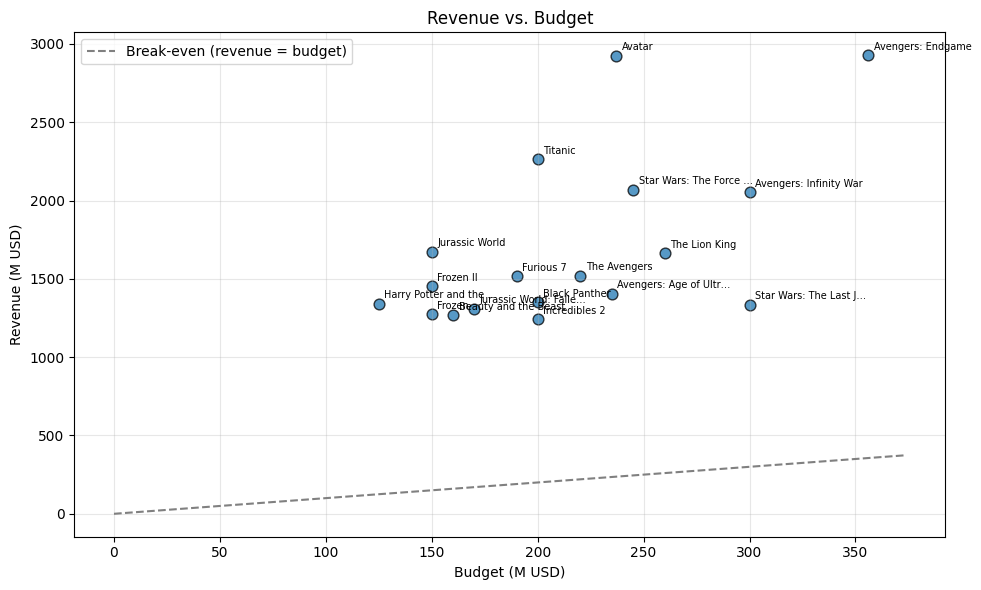

In [21]:
# ===== Step 4: Revenue vs. Budget =====
viz.plot_revenue_vs_budget(df, save_path=FIG_DIR / "revenue_vs_budget.png")
plt.show()

### ROI distribution by genre

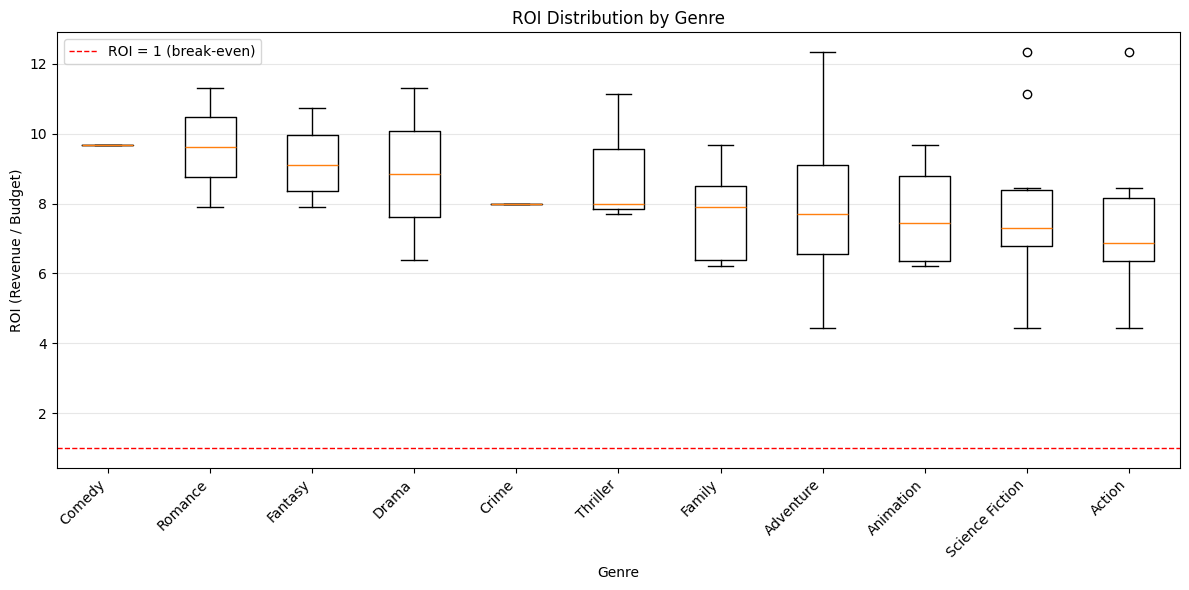

In [22]:
# ===== ROI distribution by genre =====
viz.plot_roi_by_genre(df, save_path=FIG_DIR / "roi_by_genre.png")
plt.show()

### Popularity vs. Rating

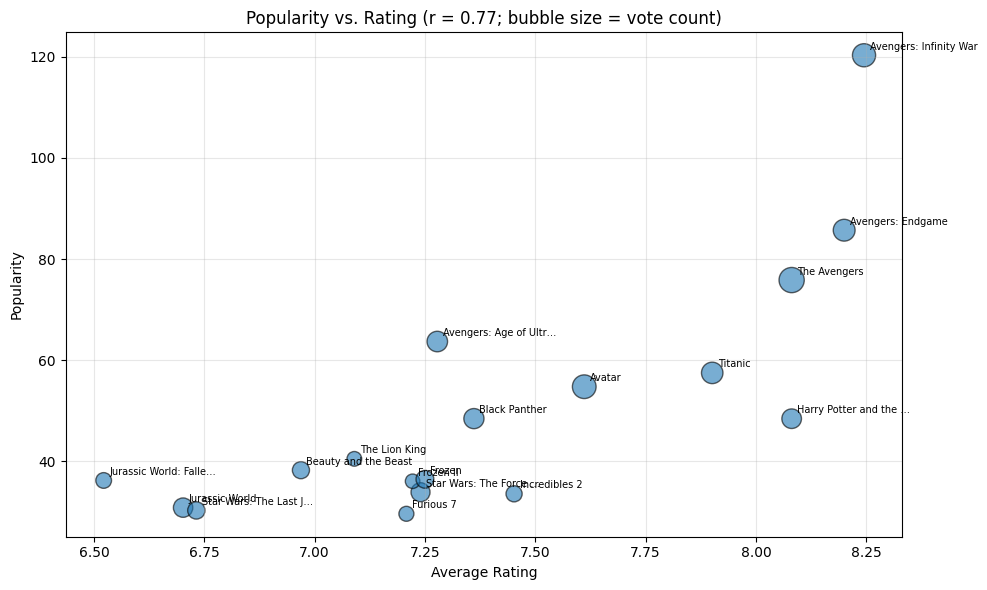

In [23]:
# ===== Popularity vs. rating =====
viz.plot_popularity_vs_rating(df, save_path=FIG_DIR / "popularity_vs_rating.png")
plt.show()

### Yearly trends in box office performance

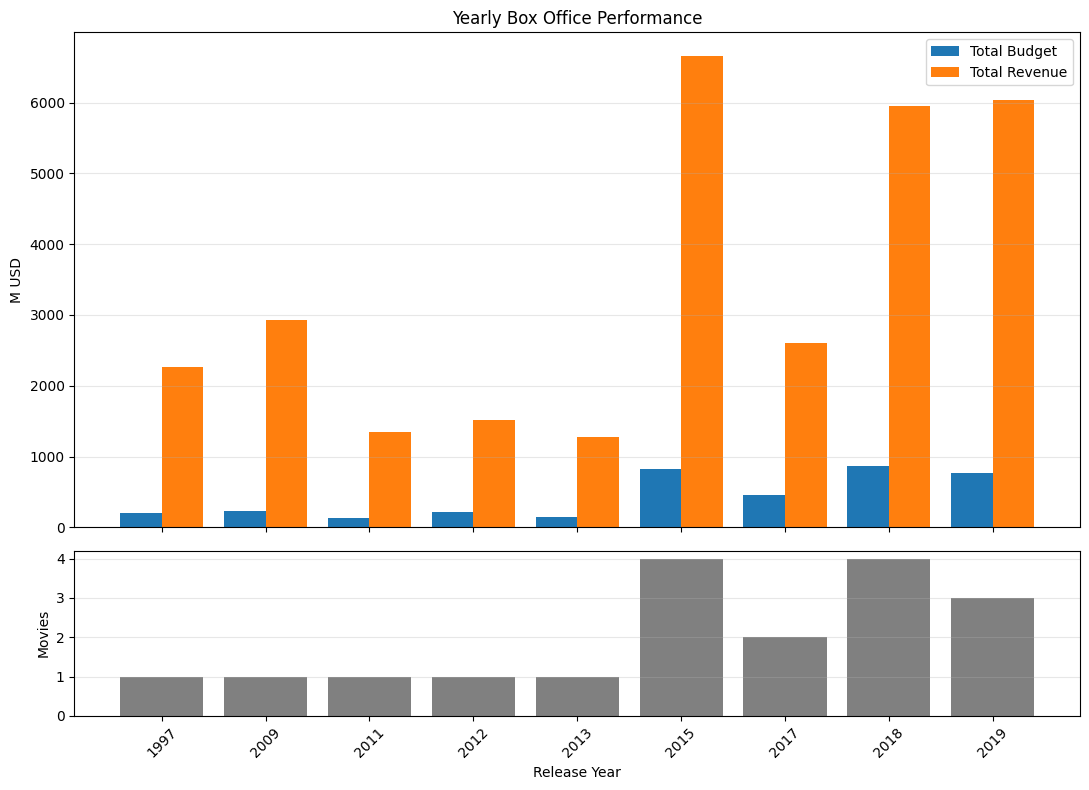

In [24]:
# ===== Yearly box office trends =====
viz.plot_yearly_trends(df, save_path=FIG_DIR / "yearly_trends.png")
plt.show()

### Franchise vs. Standalone comparison

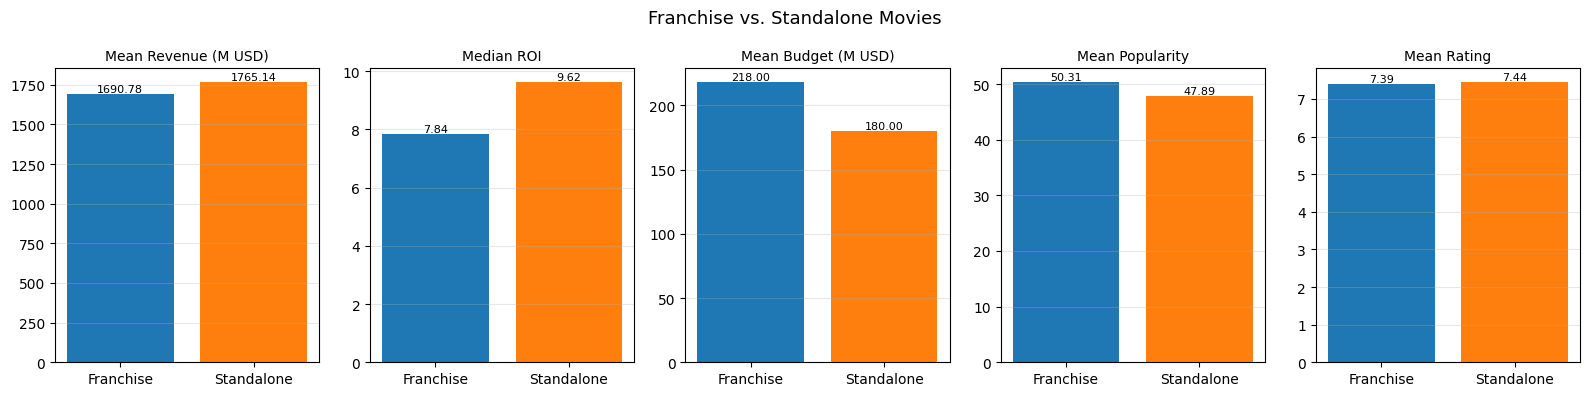

In [25]:
# ===== Franchise vs. standalone comparison =====
viz.plot_franchise_vs_standalone(franchise_summary, save_path=FIG_DIR / "franchise_vs_standalone.png")
plt.show()

## Key Insights Summary

In [27]:
# ===== Key insights summary (use these numbers in your report) =====
top_rev = df.loc[df["revenue_musd"].idxmax()]
top_roi = df[df["budget_musd"] >= 10].loc[lambda d: d["roi"].idxmax()]
fr = franchise_summary

print(f"Movies analysed: {len(df)}")
print(f"Highest revenue: {top_rev['title']} (${top_rev['revenue_musd']:,.0f}M)")
print(f"Highest ROI (budget >= $10M): {top_roi['title']} ({top_roi['roi']:.2f}x)")
print(f"Total revenue: ${df['revenue_musd'].sum():,.0f}M on ${df['budget_musd'].sum():,.0f}M budget")
print(f"Popularity vs rating correlation: {df['popularity'].corr(df['vote_average']):.2f}")
if {"Franchise", "Standalone"}.issubset(fr.index):
    ratio = fr.loc["Franchise", "mean_revenue_musd"] / fr.loc["Standalone", "mean_revenue_musd"]
    print(f"Franchise movies earn {ratio:.2f}x the mean revenue of standalone movies")

Movies analysed: 18
Highest revenue: Avengers: Endgame ($2,927M)
Highest ROI (budget >= $10M): Avatar (12.34x)
Total revenue: $30,583M on $3,848M budget
Popularity vs rating correlation: 0.77
Franchise movies earn 0.96x the mean revenue of standalone movies
